# 第4章 第4回 課題解決の過程を追体験する

### このノートブックの内容

今回は、観光案内所からの依頼をもとに、サイトへ新機能を追加します。その後、選んだ課題を改善して結果を確かめます。課題解決の過程を追体験しながら、改善の進め方を学びます。

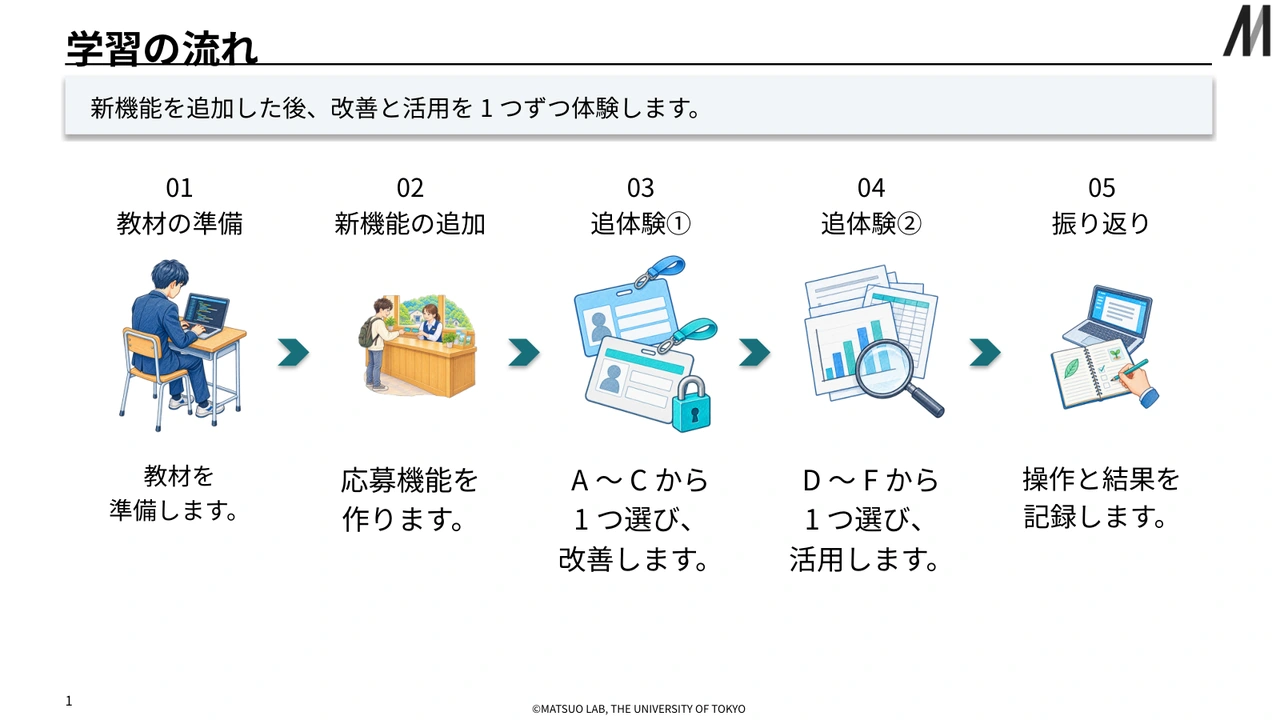

### 今回の目標

- サイトを使い、改善したい点を見つけます。
- 変えたいことをAIへ伝え、コードを動かして確かめます。
- 変更前の問題・改善後の結果・残った課題を説明します。

### 目次

1. 教材の取得と読み込み
2. 新機能の追加
3. 課題解決を追体験する①
4. 課題解決を追体験する②
5. 振り返り

## 01 教材の取得と読み込み

次のGitHubページへアクセスしてください。

[第4章4コマの教材配布ページ](https://github.com/lecture-high-school-ai-team/ch04-04-materials)

1. リポジトリ上部の「Code」→「Download ZIP」で教材を保存してください。通常は `ch04-04-materials-main.zip` という名前で保存されます。
2. 保存したZIPをパソコンで展開してください。読み込みに使うため、元のZIPも残してください。
3. 展開した演習Notebookを、次のどちらかで開いてください。
   - Colab：[Google Colab](https://colab.research.google.com/)の「ファイル」→「ノートブックをアップロード」で選んでください。
   - PyHiroba：[PyHirobaのNotebook画面](https://pyhiroba.weblab.t.u-tokyo.ac.jp/nb/)からインポートしてください。
4. 準備セルを実行した後、「教材データの読み込み」を開き、読込セルを実行してください。ファイル選択では、最初に保存したZIPを1つ選んでください。展開したフォルダを選ぶ必要はありません。
5. 「教材データを読み込みました」と表示されたら、「サンプルサイトの確認」へ進んでください。

データのコピー・貼り付けは不要です。GitHubのページが開けない場合は先生に知らせてください。

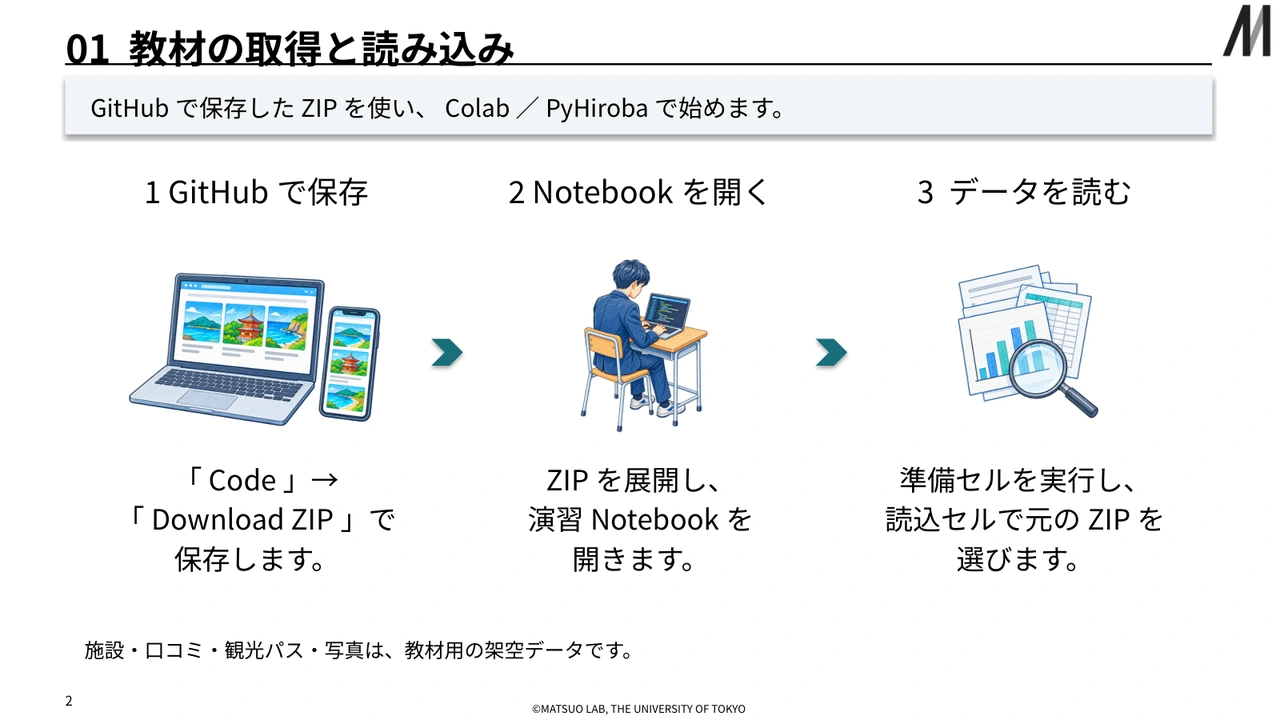


In [ ]:
# 01 準備。このセルと次のデータセルを上から実行します。
import sys
try:
    import library_hiroba
except ModuleNotFoundError:
    library_hiroba = None
if sys.platform != "emscripten" and (library_hiroba is None or library_hiroba.__version__ != "0.8.3"):
    import subprocess
    subprocess.check_call([sys.executable, "-m", "pip", "-q", "install", "-U", "library-hiroba==0.8.3"])
    for name in list(sys.modules):
        if name == "library_hiroba" or name.startswith("library_hiroba."):
            del sys.modules[name]
elif library_hiroba is None:
    raise RuntimeError("PyHirobaを新しく開き直してください。library_hirobaを使用します。")
from library_hiroba import ui
ui.alert("準備できました。次のデータセルを実行してください。", kind="success")

### 教材データの読み込み

下のセルを実行し、最初にGitHubから保存したZIP（通常は `ch04-04-materials-main.zip`）を1つ選んでください。

In [ ]:
# GitHubから保存したZIPを、Colab／PyHirobaへ読み込みます。
import io
import json
import zipfile
from google.colab import files


def load_material_bundle(material_json):
    bundle = json.loads(material_json)
    if not isinstance(bundle, dict) or bundle.get("format") != "matsuiwa-materials-v0":
        raise ValueError("第4章4コマの教材のZIPを選んでください。")
    case = bundle["case"]
    app_source = bundle["app_source"]
    feature_source = bundle["feature_source"]
    if not isinstance(case, dict) or not all(isinstance(value, str) for value in (app_source, feature_source)):
        raise ValueError("教材データの形式を確認してください。")
    globals().update(CASE=case, APP_SOURCE=app_source, FEATURE_SOURCE=feature_source)
    return ui.alert("教材データを読み込みました。次のセルへ進んでください。", kind="success")


def start_task(task="start"):
    if "CASE" not in globals():
        raise RuntimeError("先に読込セルを実行し、GitHubから保存したZIPを選んでください。")
    exec(APP_SOURCE, globals())
    exec(FEATURE_SOURCE, globals())
    return new_case(task)


print("GitHubから保存したZIP（ch04-04-materials-main.zip）を1つ選んでください。")
uploaded_materials = files.upload()
if not uploaded_materials:
    material_result = ui.alert("ファイルが選ばれていません。もう一度このセルを実行してください。", kind="warning")
else:
    candidates = []
    for filename, content in uploaded_materials.items():
        if filename.lower().endswith(".zip"):
            with zipfile.ZipFile(io.BytesIO(content)) as archive:
                names = [name for name in archive.namelist()
                         if name.replace("\\", "/").endswith("data/runtime_bundle.json")]
                if len(names) != 1:
                    raise ValueError("第4章4コマの教材のZIPを選んでください。")
                # 必要なJSONだけを読みます。ZIP内のプログラムをファイルとして展開しません。
                candidates.append(archive.read(names[0]).decode("utf-8-sig"))
        elif filename.endswith("runtime_bundle.json"):
            candidates.append(bytes(content).decode("utf-8-sig"))
    if len(candidates) != 1:
        raise ValueError("GitHubから保存したZIPを1つだけ選んでください。")
    material_result = load_material_bundle(candidates[0])
material_result


### サンプルサイトの確認

下の3つのコードセルを上から順に実行してください。施設の切り替えや短い口コミの投稿を試し、期待した動きと実際の表示を比べます。気づいたことは「最初の観察」の欄へ書いてください。

In [ ]:
app = start_task("start")
app.home()

In [ ]:
app.browse_form()

In [ ]:
app.review_form()

#### エラーが出た場合（開く）

`NameError`で`start_task`・`CASE`・`app`が未定義と表示されたら、「01 教材の取得と読み込み」の準備セル→読込セル（ZIPを選択）→「サンプルサイトの確認」の最初のセルの順に実行してください。再起動後も同じ順です。選択課題へ戻るときは、その課題の開始セルも実行します。

#### 最初の観察

---
最初の観察<font color="red">＜入力＞</font>

最初に気づいたこと：

---

## 02 新機能の追加

観光案内所から、「まついわ よりみちキャンペーン」に応募する機能を、サイトへ追加してほしいと依頼がありました。あまり知られていない灯台の丘・古城あと公園・竹林の小道を知り、訪れるきっかけを増やすための企画とのことです。

観光案内所で観光パスを購入し、訪れた対象施設の写真を送ると、抽選で景品がもらえるキャンペーンです。

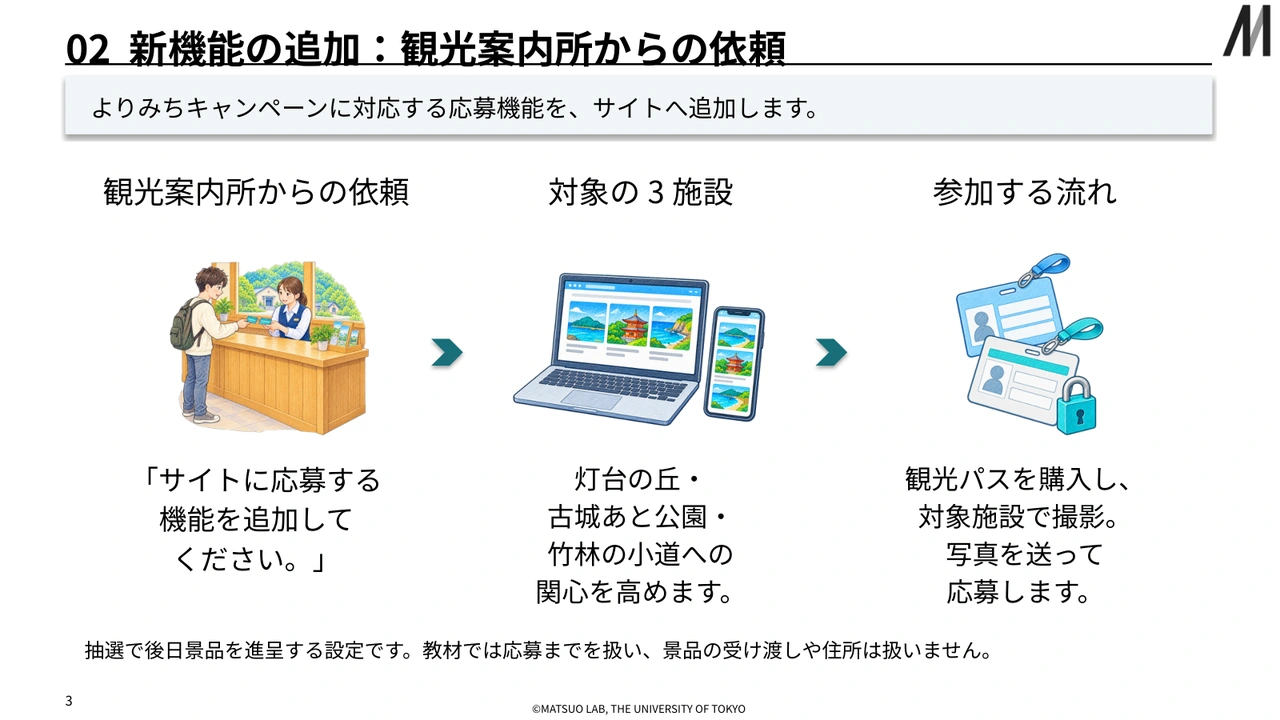

では、バイブコーディングで応募機能を作ってみましょう。バイブコーディングは、AIに希望を伝え、コードを動かして確かめながら改善する方法です。

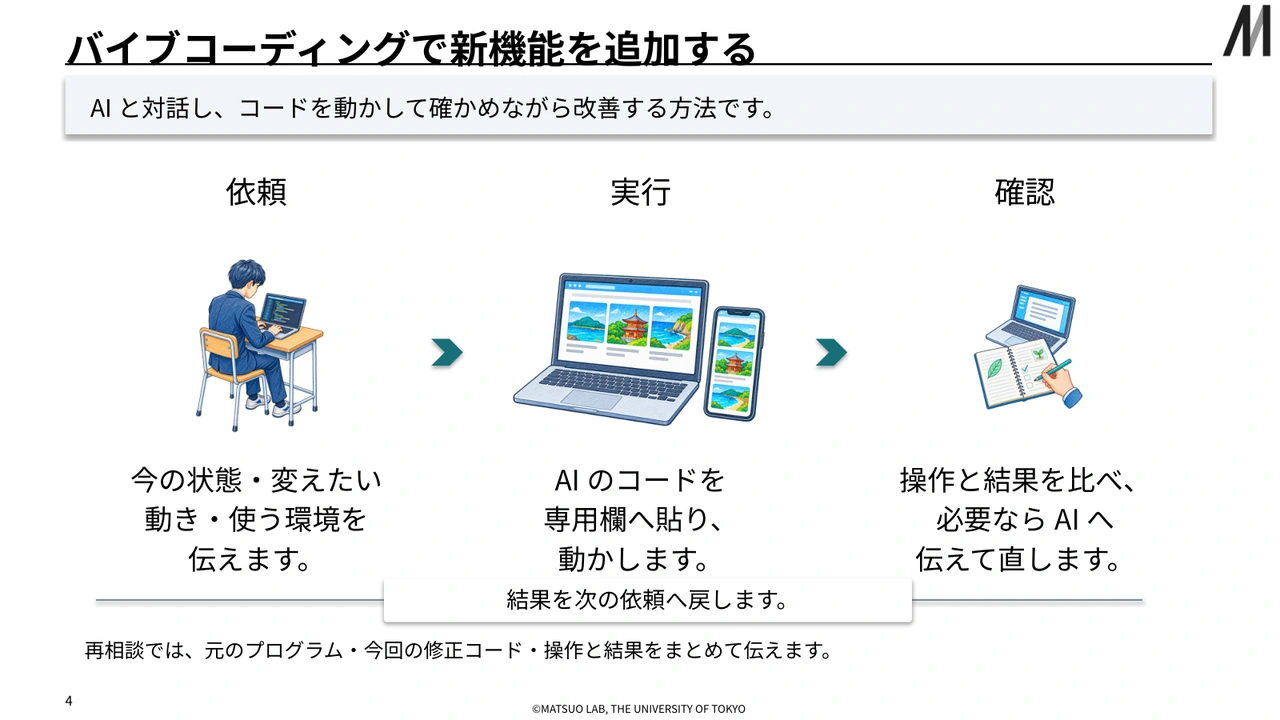

まずは、キャンペーンの応募を受け付ける機能を作ります。観光パス番号と写真で1回応募できる試作にします。応募確認コードの照合は、後の選択課題Cで扱います。ここでは、景品の受け渡しや住所は扱いません。

### 1. 参考プロンプトに一言添える

参考プロンプトを読み、その下の「自分のアイデア」に工夫したいことを一言で書きます。参考プロンプトはそのまま使えます。

参考プロンプト（コピー用）

```text
観光サイトに、写真でキャンペーンへ応募する機能を追加してください。
観光パス番号を入力し、写真を選んで送ります。
登録された未使用の観光パスで1回だけ応募でき、受付結果が分かる画面にします。
私のアイデアと、実行条件・元のプログラムを続けて渡します。
```

応募する人にとって使いやすくなる工夫を、一言で書いてください。例：「応募できたことが、画面を見てすぐ分かるようにしたい。」

「自分のアイデア：」のセルをダブルクリックして入力してください。

---
自分のアイデア（一言）<font color="red">＜入力＞</font>

自分のアイデア：

---

1. 「AIに渡すプログラムと条件」を開き、中のセルを実行してください。
2. 「参考プロンプト」→「自分のアイデア」→「セルの出力全体」の順にコピーし、まとめてご自身が使うAIへ送ってください。
3. 返ってきたPythonコードを、下の「2」で貼り付けて実行してください。

#### AIに渡すプログラムと条件（開いて実行）

下のセルは変更せずに実行してください。出力をコピーし終えたら、この見出しを閉じて「2. 返ってきたコードを実行する」へ進みます。

In [ ]:
# 実行し、表示された内容を先頭から末尾までAIへ渡します。
print('【実行条件】\nColab／PyHirobaのNotebookで実行します。library_hiroba.uiを使い、入力はui.formとui.fieldで受け取ってください。ui.htmlにscript・form・onclickを入れず、外部ファイルや新しい外部通信に依存させないでください。\nCASEは読込済みの教材データ、appは操作中のサイトです。依頼以外の動きを保ち、appの関数を置き換えるなど、1つのセルに貼って実行できるPythonコードを返してください。最後に画面や結果を表示する式を付け、確認する操作も短く教えてください。\n\n【応募機能の条件】\napp.data["passes"]の各観光パスはnumber・confirmation_code・usedを持ちます。今回はnumberだけで確認し、確認コードでの照合は追加しません。写真はapp.data["photos"]から選びます。\n登録された未使用観光パスだけ受け付け、観光パス番号と写真をapp.entriesへ記録し、その観光パスだけused=Trueにします。同じ観光パスの再応募を受け付けません。氏名・住所・景品発送は扱いません。app.campaign()で画面を開けるようにし、末尾で表示してください。\n\n【元のプログラム】\n' + APP_SOURCE)


### 2. 返ってきたコードを実行する

AIが返したPythonコードを、下のコードセルへ貼り付けて［実行］を押してください。画面が出たら「3」へ進みます。エラーが出た場合は、下の「エラーが出た場合・もう一度AIへ相談する」を開いてください。

---
AIのコードの貼り付け欄<font color="red">＜入力＞</font>

In [ ]:
# AIが返したコードをここに貼り付けて実行します。
# 必要ならコードセルを増やしてください。

---

### 3. 利用者として試す

観光パス番号「314159」と写真1で応募し、受付結果を確かめてください。

余力があれば、同じ番号でもう一度応募したり、別の番号「314160」や写真2で試したりしてください。案内文や見た目を変えても構いません。

試した結果は「4」に残します。うまく動かない場合は、次の見出しを開いてください。

### エラーが出た場合・もう一度AIへ相談する（開く）

今回実行した修正コードと、「行った操作・実際の結果・期待する結果」を同じAIとの会話へ送ってください。新しい会話で相談する場合は、上の元プログラムと実行条件も添えます。修正を複数回実行した場合は、コードと実行順を伝えます。

説明文やコードを囲む記号を貼っていないか、最初や最後の行が抜けていないか確認してください。`NameError`なら、01の準備・読込→サンプルサイトの最初のセル→今回の修正コードの順に実行します。解決しない場合は、表示されたエラーと試した操作をAIや先生へ伝えてください。

---
再依頼する内容<font color="red">＜入力＞</font>

行った操作：

実際の結果・エラー：

期待する結果：

---

### 4. 試した結果を残す

---
試したこと・結果のメモ<font color="red">＜入力＞</font>

AIへ伝えたこと：

実際に確かめた操作・結果：

次に変えたいこと：

---

### 応募画面の一例（必要なら開く）

下のセルは応募画面の一例を出します。自分で作った状態は戻るので、残したいコードは先に保存してください。選択課題は、それぞれの開始セルから始めればこの操作も不要です。

In [ ]:
# 応募画面の一例を試すときだけ実行します。
app = start_task("ready")
app.campaign()


## 03 課題解決を追体験する①

ここからは、取り組みたい課題を1つ選んで進めてください。A「不具合の修正」、B「スマホへの対応」、C「セキュリティの改善」の見出しから選びます。

課題を開いたら、開始セルから順に進みます。どの課題も初期状態から始められるため、02が未完成でも取り組めます。

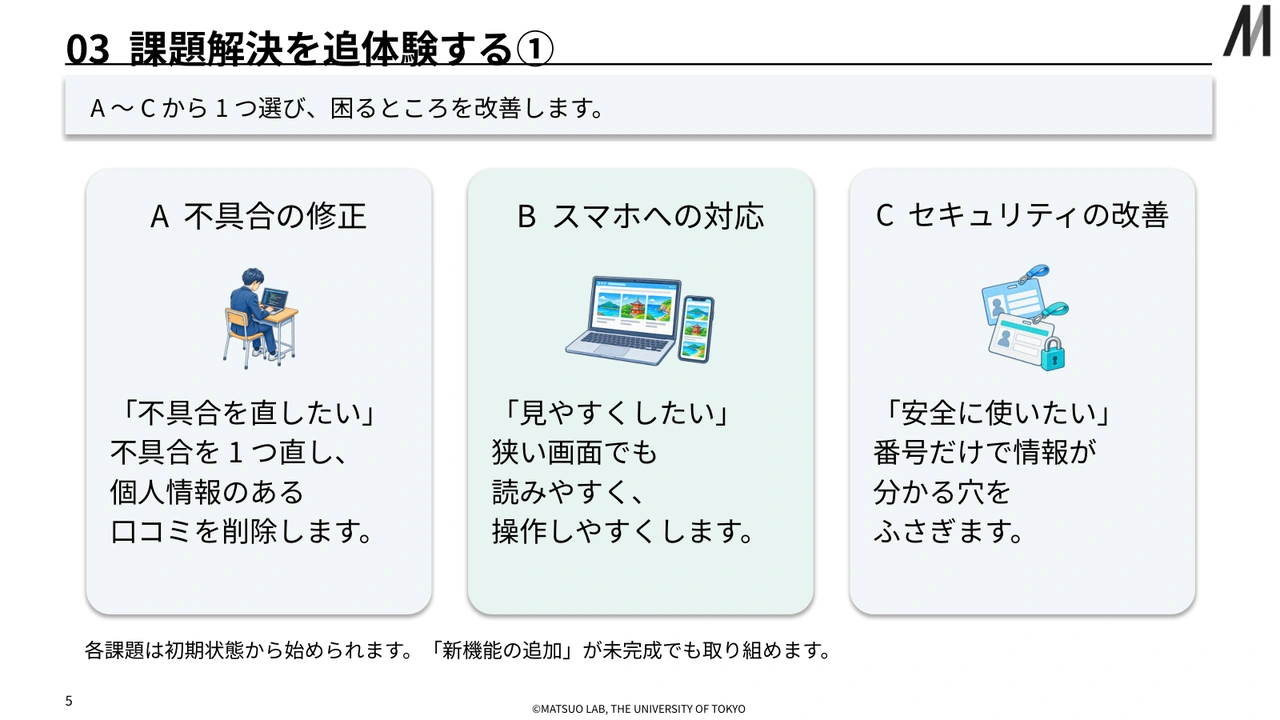

### A 不具合の修正と個人情報を含む口コミの削除

サイトを操作し、困る動きを探します。見つけた不具合を1つ選んで直し、個人情報を含む口コミは削除してください。別の問題を見つけて直しても構いません。

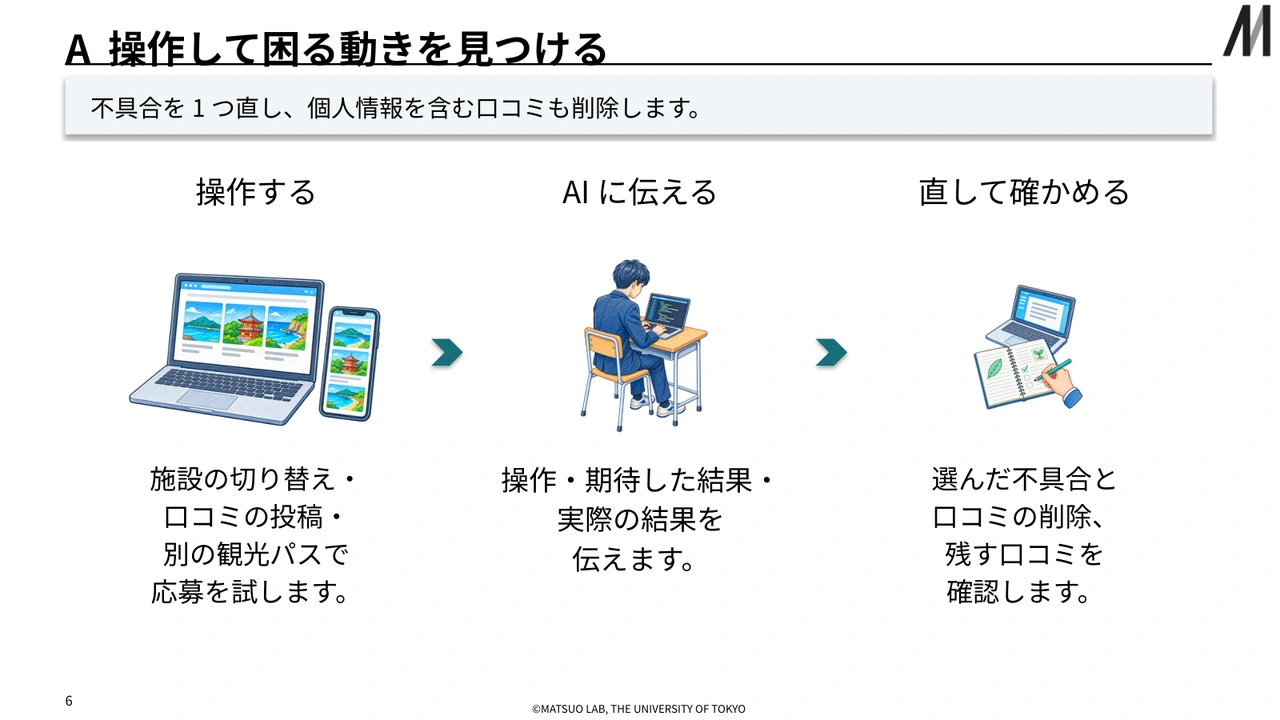

#### 1. 使って問題を見つける

下の2つのセルを上から実行し、サイトを操作したり口コミを読んだりしてください。直したい動きを1つと、個人情報を含む口コミのIDを探し、「2」の「自分のアイデア」欄へ書きます。

開始セルを再実行すると、変更や操作は初期状態へ戻ります。

In [ ]:
app = start_task("A")
ui.stack(stage_banner("A", "改善前"), ui.stack(app.home(), app.browse_form(), app.review_form(), app.campaign()))


In [ ]:
app.all_reviews()

##### 操作のヒント（困ったら開く）

施設を2か所切り替えて、タイトルと選択内容を見比べてください。口コミの投稿前後で、残っている口コミ数を見比べてください。1人が応募した後に、別の観光パスを試してください。口コミに連絡先や所属などが書かれていないか探してください。

##### 仕込まれた問題の例（自分で探してから開く）

施設を選んでも別施設の口コミが出ます。口コミの新規投稿で、もとの全口コミが消えます。1つの観光パスで応募すると全観光パスが応募済みになります。連絡先などを含む口コミもあります。直す不具合は1つで構いません。個人情報のある口コミはデータから削除してください。

口コミが消えて探せなくなったら、Aの開始セルを再実行して確認できます。

#### 2. 参考プロンプトに一言添える

参考プロンプトを読み、その下の「自分のアイデア」に工夫したいことを一言で書きます。参考プロンプトはそのまま使えます。

参考プロンプト（コピー用）

```text
観光サイトで見つけた不具合を1つ直してください。
直したい動きは、続けて伝える私のアイデアに書きます。
私が指定したIDの、個人情報を含む口コミをデータから削除し、ほかの口コミは残してください。
実行条件と元のプログラムも続けて渡します。
```

直したい動きと、削除する口コミのIDを一言で書いてください。例：「選んだ施設の口コミが出るように直し、個人情報のある口コミ（ID：自分で調べたID）を削除したい。」

---
自分のアイデア（一言）<font color="red">＜入力＞</font>

自分のアイデア：

---

1. 「AIに渡すプログラムと条件」を開き、中のセルを実行してください。
2. 「参考プロンプト」→「自分のアイデア」→「セルの出力全体」の順にコピーし、まとめてご自身が使うAIへ送ってください。
3. 返ってきたPythonコードを、下の「3」で貼り付けて実行してください。

##### AIに渡すプログラムと条件（開いて実行）

次のセルは変更せずに実行し、出力を先頭から末尾までコピーしてください。コピー後はこの見出しを閉じて「3」へ進めます。

In [ ]:
# 実行し、表示された内容を先頭から末尾までAIへ渡します。
print('【実行条件】\nColab／PyHirobaのNotebookで実行します。library_hiroba.uiを使い、入力はui.formとui.fieldで受け取ってください。ui.htmlにscript・form・onclickを入れず、外部ファイルや新しい外部通信に依存させないでください。\nCASEは読込済みの教材データ、appは操作中のサイトです。依頼以外の動きを保ち、appの関数を置き換えるなど、1つのセルに貼って実行できるPythonコードを返してください。最後に画面や結果を表示する式を付け、確認する操作も短く教えてください。\n\n【Aの条件】\n選んだ不具合1つを直し、指定された口コミIDをapp.data["reviews"]から削除してください。他の口コミは残します。表示だけのマスクや投稿監視機能の追加は不要です。依頼していない不具合までまとめて変更しないでください。\n\n【元のプログラム】\n' + APP_SOURCE + "\n\n" + FEATURE_SOURCE)


#### 3. 返ってきたコードを実行する

AIの返答からPythonコードだけをコピーし、下のA専用セルへ貼り付けて［実行］を押してください。説明文やコードを囲む記号は貼り付けません。続けて「4」で確かめます。

---
AIのコードの貼り付け欄<font color="red">＜入力＞</font>

In [ ]:
# A：AIが返したコードをここに貼り付けて実行してください。
# 必要なら、この課題の中にコードセルを増やしてください。

---

#### 4. 動きと結果を確かめる

下のセルを実行し、次の3点を順に確かめてください。

1. 選んだ不具合の操作だけをもう一度試し、期待した結果になるか確かめます。
2. 削除した口コミIDが一覧に残っていないか確認します。
3. 残しておく口コミが消えていないか確認します。

結果を「5」に書きます。直したい点が残ったら「もう一度AIへ相談する」を開いてください。

In [ ]:
ui.stack(stage_banner("A", "改善後（確認中）"), ui.stack(app.home(), app.browse_form(), app.review_form(), app.campaign(), app.all_reviews()))


#### もう一度AIへ相談する（必要なら開く）

今回実行した修正コードと、下の3点を同じAIとの会話へ送ります。新しい会話では「2」の元プログラムと実行条件も添えてください。複数の修正を実行した場合は、そのコードと順番も伝えます。

返ってきたコードを「3」に貼り付けて実行し、「4」で同じ操作を試します。この繰り返しでは開始セルを実行し直しません。

---
再依頼する内容<font color="red">＜入力＞</font>

行った操作：

実際の結果・エラー：

期待する結果：

---

#### 5. 試した結果を残す

---
試したこと・結果のメモ<font color="red">＜入力＞</font>

変更前の問題・AIへ伝えたこと：

選んだ不具合と、同じ操作を試した結果：

削除した口コミIDと、削除を確認した結果：

残しておく口コミが残っているかを確認した結果：

残った課題・次に試したいこと：

---

変更前の問題・改善後の結果・残った課題を説明できたら、この課題は一区切りです。

### B PC向け画面のスマホへの対応

今のサイトはPC向けに横幅が固定されています。スマホでも読み、操作できるように変更しましょう。

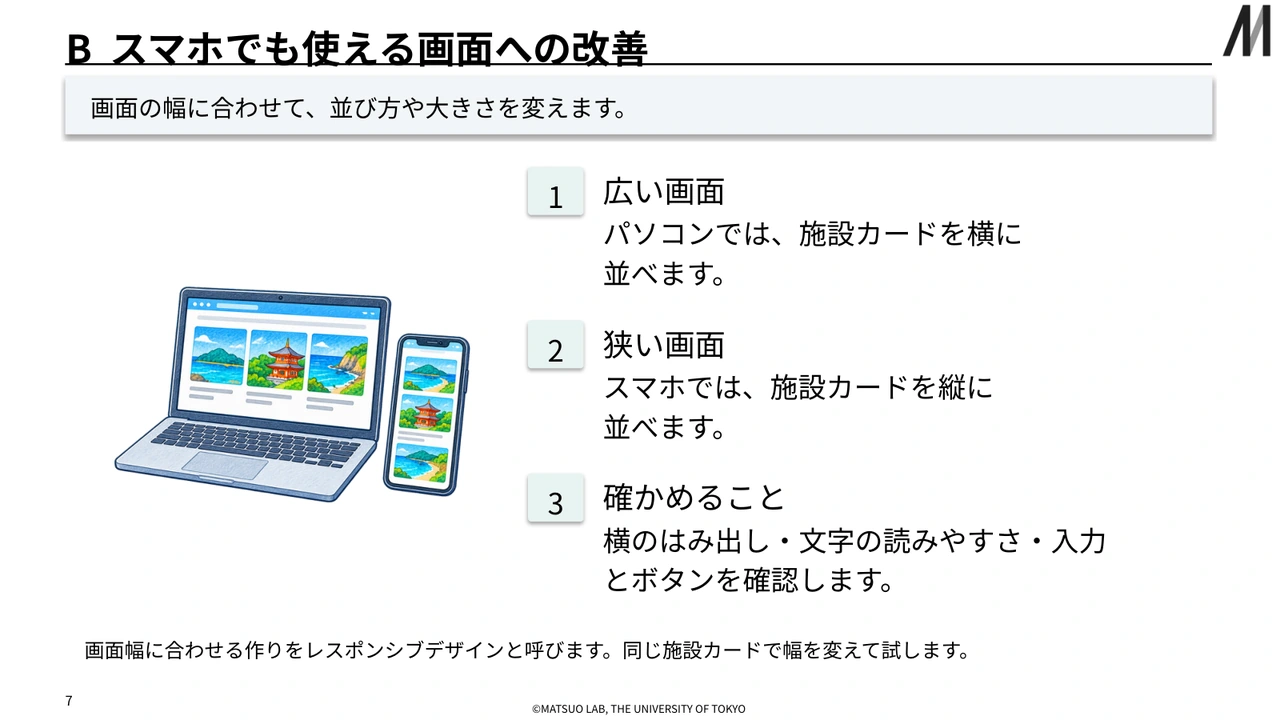

ブラウザの開発者ツールのデバイス表示や、狭くしたウィンドウで試します。実際のスマホで開ける人は実機でも確かめられます。目安の幅は390pxですが、別の幅も試せます。Notebookの左右の余白と、サイト自身のはみ出しを見分けましょう。

#### 1. 使って問題を見つける

下のセルを実行し、ウィンドウの幅を狭くしてサイトを見てください。読みにくい所や操作しにくい所を見つけ、「2」の「自分のアイデア」欄へ書きます。

開始セルを再実行すると、変更や操作は初期状態へ戻ります。

In [ ]:
app = start_task("B")
ui.stack(stage_banner("B", "改善前"), app.home())


#### 2. 参考プロンプトに一言添える

参考プロンプトを読み、その下の「自分のアイデア」に工夫したいことを一言で書きます。参考プロンプトはそのまま使えます。

参考プロンプト（コピー用）

```text
観光サイトを、PCでもスマホでも使える画面にしてください。
狭い画面では施設カードを縦に並べ、文字・写真・入力欄・ボタンが横にはみ出さないようにします。
見やすくする工夫は、続けて伝える私のアイデアに合わせてください。
実行条件と元のプログラムも渡します。
```

特に見やすくしたい所や、操作しやすくする工夫を一言で書いてください。例：「写真の下に施設名を大きく表示したい。」

---
自分のアイデア（一言）<font color="red">＜入力＞</font>

自分のアイデア：

---

1. 「AIに渡すプログラムと条件」を開き、中のセルを実行してください。
2. 「参考プロンプト」→「自分のアイデア」→「セルの出力全体」の順にコピーし、まとめてご自身が使うAIへ送ってください。
3. 返ってきたPythonコードを、下の「3」で貼り付けて実行してください。

##### AIに渡すプログラムと条件（開いて実行）

次のセルは変更せずに実行し、出力を先頭から末尾までコピーしてください。コピー後はこの見出しを閉じて「3」へ進めます。

In [ ]:
# 実行し、表示された内容を先頭から末尾までAIへ渡します。
print('【実行条件】\nColab／PyHirobaのNotebookで実行します。library_hiroba.uiを使い、入力はui.formとui.fieldで受け取ってください。ui.htmlにscript・form・onclickを入れず、外部ファイルや新しい外部通信に依存させないでください。\nCASEは読込済みの教材データ、appは操作中のサイトです。依頼以外の動きを保ち、appの関数を置き換えるなど、1つのセルに貼って実行できるPythonコードを返してください。最後に画面や結果を表示する式を付け、確認する操作も短く教えてください。\n\n【Bの条件】\napp.home()と必要な表示を変更します。最小限の変更から始め、画面幅に合わせて表示し、広いPC画面でも使えるようにします。末尾でapp.home()を表示してください。\n\n【元のプログラム】\n' + APP_SOURCE + "\n\n" + FEATURE_SOURCE)


#### 3. 返ってきたコードを実行する

AIの返答からPythonコードだけをコピーし、下のB専用セルへ貼り付けて［実行］を押してください。説明文やコードを囲む記号は貼り付けません。続けて「4」で確かめます。

---
AIのコードの貼り付け欄<font color="red">＜入力＞</font>

In [ ]:
# B：AIが返したコードをここに貼り付けて実行してください。
# 必要なら、この課題の中にコードセルを増やしてください。

---

#### 4. 動きと結果を確かめる

下のセルを実行し、広い画面と狭い画面を比べてください。横のはみ出し、文字の読みやすさ、入力欄やボタンの使いやすさを確認し、結果を「5」に書きます。

In [ ]:
ui.stack(stage_banner("B", "改善後（確認中）"), app.home())


#### もう一度AIへ相談する（必要なら開く）

今回実行した修正コードと、下の3点を同じAIとの会話へ送ります。新しい会話では「2」の元プログラムと実行条件も添えてください。複数の修正を実行した場合は、そのコードと順番も伝えます。

返ってきたコードを「3」に貼り付けて実行し、「4」で同じ操作を試します。この繰り返しでは開始セルを実行し直しません。

---
再依頼する内容<font color="red">＜入力＞</font>

行った操作：

実際の結果・エラー：

期待する結果：

---

#### 5. 試した結果を残す

---
試したこと・結果のメモ<font color="red">＜入力＞</font>

変更前の問題・AIへ伝えたこと：

実際に確かめた操作・結果：

残った課題・次に試したいこと：

---

変更前の問題・改善後の結果・残った課題を説明できたら、この課題は一区切りです。

### C セキュリティの改善

セキュリティは、情報や機能を安全に使えるように守ることです。今のサイトには、短い番号を試すだけで、観光パスの登録や応募の状態を調べられてしまう穴があります。観光パス番号は「どの観光パスか」を示し、裏面の応募確認コードは利用するための秘密の値です。組み合わせを照合し、穴をふさぐ改善を試します。両方が知られた場合の利用まで防げるわけではありません。

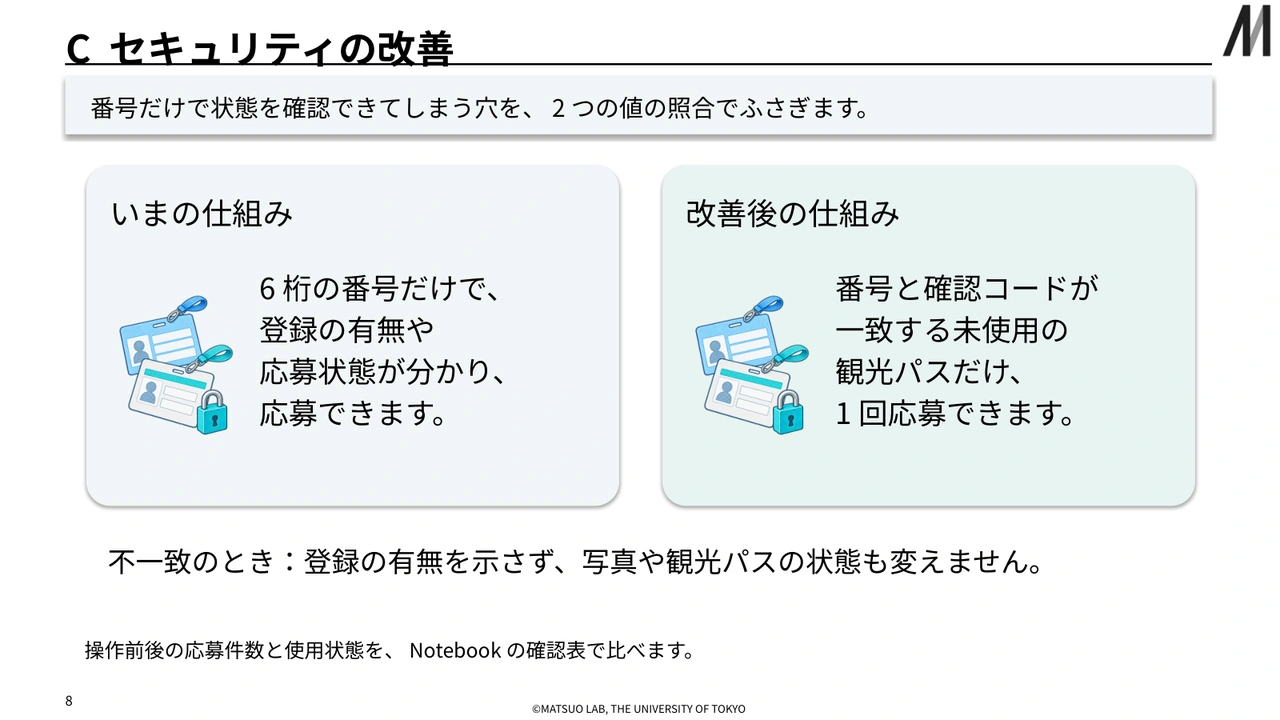

#### 1. 使って問題を見つける

下の2つのセルを上から実行してください。番号だけで観光パスの登録や応募の状態が分かることを確かめます。確認用の番号は「確認に使う観光パス」を開いて参照できます。

開始セルを再実行すると、変更や操作は初期状態へ戻ります。

In [ ]:
app = start_task("C")
ui.stack(stage_banner("C", "改善前"), app.campaign())


In [ ]:
ui.stack(*(ui.card(str(number), app.lookup_pass(str(number)))
           for number in range(314158, 314163)))

##### 改善の目安・発展案

まずは2つのコードの組み合わせを照合します。不一致なら登録の有無を区別しない表示にし、写真や使用状態を変更しません。正しい組み合わせは1回だけ応募できます。

発展として、試行回数の制限、時間を置く仕組み、記録の確認などを紹介できます。今回は実装を必須にしません。

##### 確認に使う観光パス（開いて実行）

下のセルで、練習用の番号・応募確認コード・初期状態を確認できます。番号は「どの観光パスか」、確認コードは利用のための秘密の値です。両方を照合する改善を試します。

In [ ]:
ui.table([[p["number"], p["confirmation_code"], "応募済み" if p["used"] else "未応募"] for p in CASE["passes"]], headers=["観光パス番号", "応募確認コード", "初期状態"])


#### 2. 参考プロンプトに一言添える

参考プロンプトを読み、その下の「自分のアイデア」に工夫したいことを一言で書きます。参考プロンプトはそのまま使えます。

参考プロンプト（コピー用）

```text
番号だけで観光パスの状態が分かり、応募できる問題を直してください。
番号と確認コードが一致する未応募の観光パスだけ、1回応募できるようにします。
不一致なら登録の有無や応募状態を明かさず、応募データも変更しないでください。
私のアイデアと、実行条件・元のプログラムを続けて渡します。
```

上の安全の条件を保ったまま、案内文や画面で工夫したいことを一言で書いてください。例：「入力が合わないときは、確認してほしいことを短く案内したい。」

---
自分のアイデア（一言）<font color="red">＜入力＞</font>

自分のアイデア：

---

1. 「AIに渡すプログラムと条件」を開き、中のセルを実行してください。
2. 「参考プロンプト」→「自分のアイデア」→「セルの出力全体」の順にコピーし、まとめてご自身が使うAIへ送ってください。
3. 返ってきたPythonコードを、下の「3」で貼り付けて実行してください。

##### AIに渡すプログラムと条件（開いて実行）

次のセルは変更せずに実行し、出力を先頭から末尾までコピーしてください。コピー後はこの見出しを閉じて「3」へ進めます。

In [ ]:
# 実行し、表示された内容を先頭から末尾までAIへ渡します。
print('【実行条件】\nColab／PyHirobaのNotebookで実行します。library_hiroba.uiを使い、入力はui.formとui.fieldで受け取ってください。ui.htmlにscript・form・onclickを入れず、外部ファイルや新しい外部通信に依存させないでください。\nCASEは読込済みの教材データ、appは操作中のサイトです。依頼以外の動きを保ち、appの関数を置き換えるなど、1つのセルに貼って実行できるPythonコードを返してください。最後に画面や結果を表示する式を付け、確認する操作も短く教えてください。\n\n【Cの条件】\napp.data["passes"]のnumberとconfirmation_codeの両方を照合します。不一致なら、登録の有無・使用状態で案内を変えず、写真を保存せず、usedも変えません。一致する未使用観光パスだけ1回受け付けます。\ncampaign_submit、app.lookup_pass、必要な入力画面を変更し、末尾でapp.campaign()を表示してください。回数制限などの追加機能は不要です。\n\n【元のプログラム】\n' + APP_SOURCE + "\n\n" + FEATURE_SOURCE)


#### 3. 返ってきたコードを実行する

AIの返答からPythonコードだけをコピーし、下のC専用セルへ貼り付けて［実行］を押してください。説明文やコードを囲む記号は貼り付けません。続けて「4」で確かめます。

---
AIのコードの貼り付け欄<font color="red">＜入力＞</font>

In [ ]:
# C：AIが返したコードをここに貼り付けて実行してください。
# 必要なら、この課題の中にコードセルを増やしてください。

---

#### 4. 動きと結果を確かめる

正しい組み合わせ、不一致、応募済みの観光パスで試します。条件を変えるたび、次の1〜3を繰り返してください。

1. 下の確認セルを実行します。操作前の応募件数と観光パスの状態を記録します。
2. 表示された画面で応募します。
3. 「操作後のデータ」のセルを実行し、操作前と比べます。

開始セルは実行し直しません。結果を「5」に書きます。

In [ ]:
campaign_state_before = campaign_snapshot(app)
ui.stack(stage_banner("C", "改善後（確認中）"), app.campaign())


##### 操作後のデータ

応募した後に実行してください。不一致の入力では、応募件数と各観光パスの状態が変わっていないか確認します。

In [ ]:
campaign_state_report(app, campaign_state_before)


#### もう一度AIへ相談する（必要なら開く）

今回実行した修正コードと、下の3点を同じAIとの会話へ送ります。新しい会話では「2」の元プログラムと実行条件も添えてください。複数の修正を実行した場合は、そのコードと順番も伝えます。

返ってきたコードを「3」に貼り付けて実行し、「4」で同じ操作を試します。この繰り返しでは開始セルを実行し直しません。

---
再依頼する内容<font color="red">＜入力＞</font>

行った操作：

実際の結果・エラー：

期待する結果：

---

#### 5. 試した結果を残す

---
試したこと・結果のメモ<font color="red">＜入力＞</font>

変更前の問題・AIへ伝えたこと：

実際に確かめた操作・結果：

残った課題・次に試したいこと：

---

変更前の問題・改善後の結果・残った課題を説明できたら、この課題は一区切りです。

## 04 課題解決を追体験する②

D「データで比較する」、E「写真を見分ける」、F「意味で検索する」から、取り組みたい課題を1つ選んで開いてください。開始セルから順に進め、問いや判断基準を自分で決めて確かめます。Fの検索に外部APIは使いません。

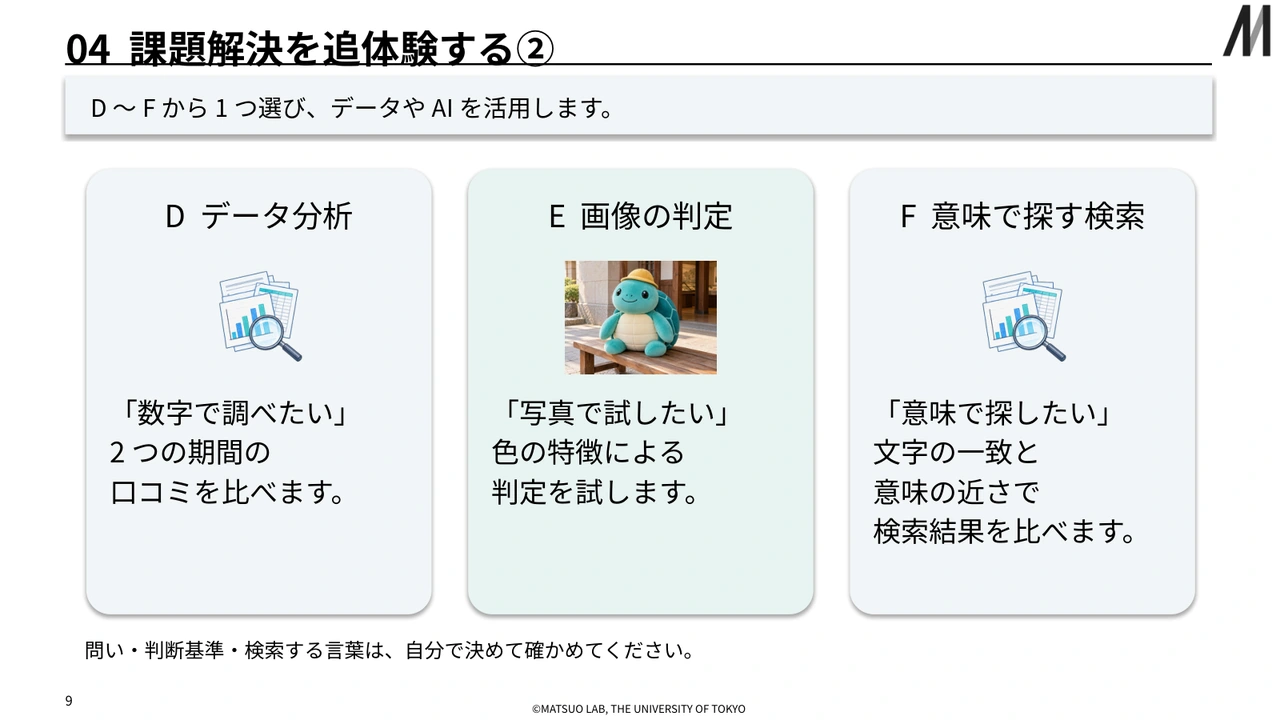

### D キャンペーン期間と通常期間の比較

キャンペーンは、あまり知られていなかった施設を知り、訪れるきっかけを増やすために実施されました。何を指標に比べるか、自分で決めましょう。

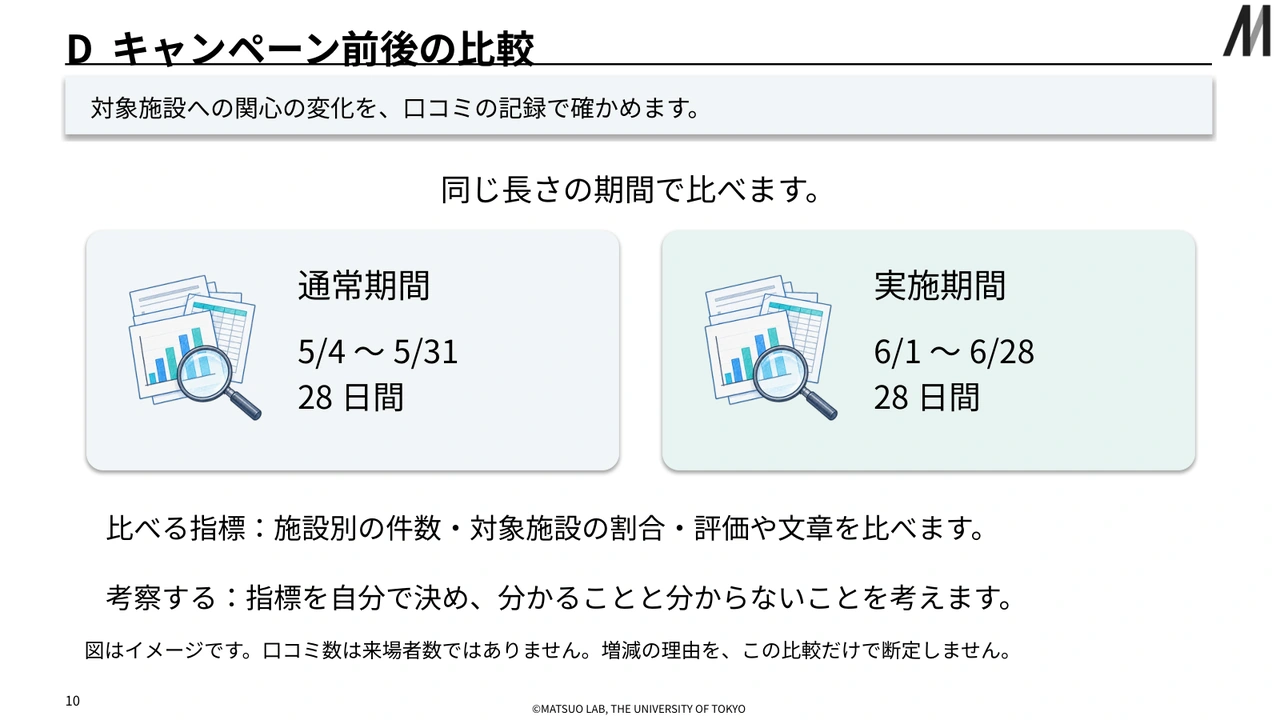

#### 1. 試して調べたいことを決める

下のセルを実行し、2つの期間の口コミ数を確認してください。何をどの指標で比べたいかを考え、「2」の「自分のアイデア」欄へ一言で書きます。

開始セルを再実行すると、変更や操作は初期状態へ戻ります。

In [ ]:
app = start_task("D")
ui.stack(stage_banner("D", "改善前"), app.analysis())


##### 使えるデータ・考えるヒント

施設情報はapp.data["places"]、口コミはapp.data["reviews"]です。サイト情報と口コミを1つのデータにまとめています。施設のidと口コミのplace_idで対応し、campaign_targetが対象施設の印、periodが期間です。どちらも28日間です。

全体の口コミが増えたかだけでなく、対象施設ごとの件数や、全体の中の割合も比べられます。口コミは来場者全員の記録ではありません。ほかの出来事などの影響も考えましょう。

#### 2. 参考プロンプトに一言添える

参考プロンプトを読み、その下の「自分のアイデア」に工夫したいことを一言で書きます。参考プロンプトはそのまま使えます。

参考プロンプト（コピー用）

```text
通常期間とキャンペーン期間の口コミを、表かグラフで比べたいです。
続けて伝える私のアイデアに書いた問いと指標に沿って、結果を表示してください。
口コミ数を来場者数と同じ意味で扱わないでください。
実行条件と元のプログラムも渡します。
```

何をどの指標で比べたいかを、一言で書いてください。例：「対象施設の口コミが全体に占める割合は増えたか、棒グラフで比べたい。」

---
自分のアイデア（一言）<font color="red">＜入力＞</font>

自分のアイデア：

---

1. 「AIに渡すプログラムと条件」を開き、中のセルを実行してください。
2. 「参考プロンプト」→「自分のアイデア」→「セルの出力全体」の順にコピーし、まとめてご自身が使うAIへ送ってください。
3. 返ってきたPythonコードを、下の「3」で貼り付けて実行してください。

##### AIに渡すプログラムと条件（開いて実行）

次のセルは変更せずに実行し、出力を先頭から末尾までコピーしてください。コピー後はこの見出しを閉じて「3」へ進めます。

In [ ]:
# 実行し、表示された内容を先頭から末尾までAIへ渡します。
print('【実行条件】\nColab／PyHirobaのNotebookで実行します。library_hiroba.uiを使い、入力はui.formとui.fieldで受け取ってください。ui.htmlにscript・form・onclickを入れず、外部ファイルや新しい外部通信に依存させないでください。\nCASEは読込済みの教材データ、appは操作中のサイトです。依頼以外の動きを保ち、appの関数を置き換えるなど、1つのセルに貼って実行できるPythonコードを返してください。最後に画面や結果を表示する式を付け、確認する操作も短く教えてください。\n\n【Dのデータ】\napp.data["places"]とapp.data["reviews"]を使います。施設のidと口コミのplace_idが対応し、campaign_targetが対象施設の印、periodが期間です。両期間とも28日間です。Python標準ライブラリとlibrary_hiroba.uiで動く形にし、結果を表示してください。\n\n【元のプログラム】\n' + APP_SOURCE + "\n\n" + FEATURE_SOURCE)


#### 3. 返ってきたコードを実行する

AIの返答からPythonコードだけをコピーし、下のD専用セルへ貼り付けて［実行］を押してください。説明文やコードを囲む記号は貼り付けません。続けて「4」で確かめます。

---
AIのコードの貼り付け欄<font color="red">＜入力＞</font>

In [ ]:
# D：AIが返したコードをここに貼り付けて実行してください。
# 必要なら、この課題の中にコードセルを増やしてください。

---

改善後（確認中）：上の実行結果を、選んだ指標で確かめてください。出力が表示されただけでは、集計や判断が正しいとは限りません。

#### 4. 動きと結果を確かめる

「3」で表示された表やグラフを見て、自分の指標で2つの期間を比べてください。口コミ数だけで来場者数や増減の理由を断定せず、分かったことと分からないことを「5」に書きます。

#### もう一度AIへ相談する（必要なら開く）

今回実行した修正コードと、下の3点を同じAIとの会話へ送ります。新しい会話では「2」の元プログラムと実行条件も添えてください。複数の修正を実行した場合は、そのコードと順番も伝えます。

返ってきたコードを「3」に貼り付けて実行し、「4」で同じ操作を試します。この繰り返しでは開始セルを実行し直しません。

---
再依頼する内容<font color="red">＜入力＞</font>

行った操作：

実際の結果・エラー：

期待する結果：

---

#### 5. 試した結果を残す

---
試したこと・結果のメモ<font color="red">＜入力＞</font>

変更前の問題・AIへ伝えたこと：

実際に確かめた操作・結果：

残った課題・次に試したいこと：

---

変更前の問題・改善後の結果・残った課題を説明できたら、この課題は一区切りです。

### E 写真の特徴から、まつぽんの写真を見分ける

別のマスコットの写真も送られてきました。まずは色などの簡単な特徴を使って、写真を見分ける目安を作りましょう。画像認識は、画像から特徴を取り出し、対象を見分ける処理です。今回は色の割合から決めたルールを試します。写真を大量に学習させる処理は行いません。

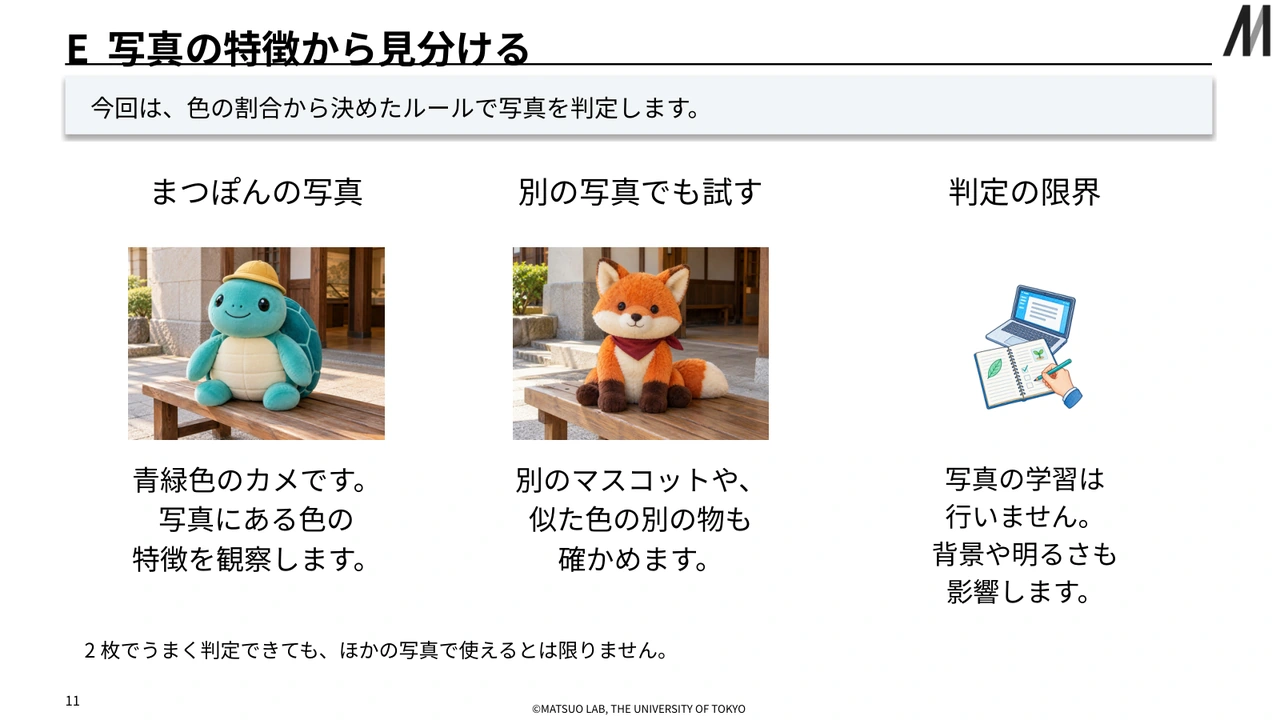

#### 1. 試して調べたいことを決める

下のセルを実行し、2枚の写真を見比べてください。まつぽんの色の特徴に注目し、「2」の「自分のアイデア」欄へ書きます。

開始セルを再実行すると、変更や操作は初期状態へ戻ります。

In [ ]:
app = start_task("E")
ui.stack(stage_banner("E", "改善前"), ui.columns(app.photo_preview("写真1"), app.photo_preview("写真2")))


#### 2. 参考プロンプトに一言添える

参考プロンプトを読み、その下の「自分のアイデア」に工夫したいことを一言で書きます。参考プロンプトはそのまま使えます。

参考プロンプト（コピー用）

```text
写真の色から、まつぽん（青緑色のカメ・黄色い帽子）らしいかを判定する目安を作ってください。
私のアイデアに書いた色の特徴を使い、判定と特徴の値を表示します。
基準を後で変えられるようにし、写真の名前を答えとして使わないでください。
実行条件と元のプログラムも続けて渡します。
```

注目した色と、どのように比べたいかを一言で書いてください。例：「青緑色が写真の中にどのくらいあるかを使って判定したい。」

---
自分のアイデア（一言）<font color="red">＜入力＞</font>

自分のアイデア：

---

1. 「AIに渡すプログラムと条件」を開き、中のセルを実行してください。
2. 「参考プロンプト」→「自分のアイデア」→「セルの出力全体」の順にコピーし、まとめてご自身が使うAIへ送ってください。
3. 返ってきたPythonコードを、下の「3」で貼り付けて実行してください。

##### AIに渡すプログラムと条件（開いて実行）

次のセルは変更せずに実行し、出力を先頭から末尾までコピーしてください。コピー後はこの見出しを閉じて「3」へ進めます。

In [ ]:
# 実行し、表示された内容を先頭から末尾までAIへ渡します。
print('【実行条件】\nColab／PyHirobaのNotebookで実行します。library_hiroba.uiを使い、入力はui.formとui.fieldで受け取ってください。ui.htmlにscript・form・onclickを入れず、外部ファイルや新しい外部通信に依存させないでください。\nCASEは読込済みの教材データ、appは操作中のサイトです。依頼以外の動きを保ち、appの関数を置き換えるなど、1つのセルに貼って実行できるPythonコードを返してください。最後に画面や結果を表示する式を付け、確認する操作も短く教えてください。\n\n【Eのデータと条件】\napp.data["photos"][写真名]はimageとrgbを持ちます。rgbは32×32画素のR,G,Bが順番に並ぶ整数リストです。実際のrgb値から色の割合などを求め、標準ライブラリだけで動くapp.classify_photo(photo)を作ります。\n判定の目安と特徴の値を表示し、名前やlabelを正解として使わないでください。判定が難しい場合を「要確認」としても構いません。本物や不正を証明する判定ではありません。末尾に判定画面か結果を表示してください。\n\n【元のプログラム】\n' + APP_SOURCE + "\n\n" + FEATURE_SOURCE)


#### 3. 返ってきたコードを実行する

AIの返答からPythonコードだけをコピーし、下のE専用セルへ貼り付けて［実行］を押してください。説明文やコードを囲む記号は貼り付けません。続けて「4」で確かめます。

---
AIのコードの貼り付け欄<font color="red">＜入力＞</font>

In [ ]:
# E：AIが返したコードをここに貼り付けて実行してください。
# 必要なら、この課題の中にコードセルを増やしてください。

---

#### 4. 動きと結果を確かめる

下のセルを実行し、写真を1枚ずつ選んで判定してください。使った特徴の値と結果を見比べ、背景や明るさ、似た色の別の物で間違いそうかも考えます。本人の撮影や不正を証明する判定ではありません。結果を「5」に書きます。

In [ ]:
ui.stack(stage_banner("E", "改善後（確認中）"), ui.form(app.classify_photo,
    ui.field("photo", "判定する写真", kind="choice", choices=app.photo_keys),
    submit_label="写真を確かめる", clear_on_submit=False))


#### もう一度AIへ相談する（必要なら開く）

今回実行した修正コードと、下の3点を同じAIとの会話へ送ります。新しい会話では「2」の元プログラムと実行条件も添えてください。複数の修正を実行した場合は、そのコードと順番も伝えます。

返ってきたコードを「3」に貼り付けて実行し、「4」で同じ操作を試します。この繰り返しでは開始セルを実行し直しません。

---
再依頼する内容<font color="red">＜入力＞</font>

行った操作：

実際の結果・エラー：

期待する結果：

---

#### 5. 試した結果を残す

---
試したこと・結果のメモ<font color="red">＜入力＞</font>

変更前の問題・AIへ伝えたこと：

実際に確かめた操作・結果：

残った課題・次に試したいこと：

---

変更前の問題・改善後の結果・残った課題を説明できたら、この課題は一区切りです。

### F キーワード検索と意味検索の比較

施設の紹介文に同じ言葉がなくても、意味の近さから観光地を探す機能を作ります。まず文字の一致で探し、次に学習済みの単語ベクトルを使う検索へ改善します。

単語ベクトルは、言葉を数値の並びで表したものです。今回は教材用の観光文から、word2vecという方法で事前に学習した88語の数値を使います。この場で新たに学習する操作や、外部APIへの接続は行いません。

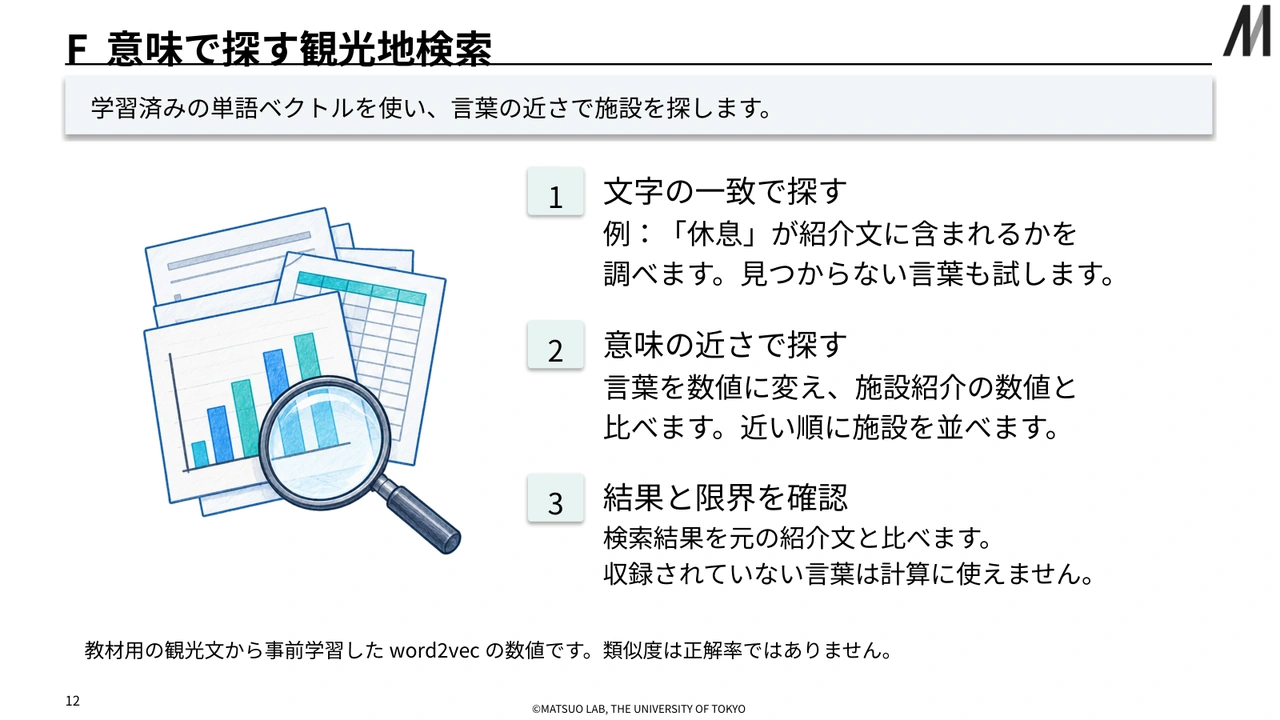

#### 1. 試して調べたいことを決める

下のセルを実行し、「休息」などの言葉で検索してください。紹介文に同じ文字がないと見つからないことを確かめ、「2」の「自分のアイデア」欄へ試したい検索語や工夫を書きます。

開始セルを再実行すると、変更や操作は初期状態へ戻ります。

In [ ]:
app = start_task("F")
ui.stack(stage_banner("F", "改善前"), app.keyword_form())


##### 検索に使う数値と、その限界

教材用の合成観光文341文から、単語の周りに出る言葉を手掛かりに、88語をそれぞれ32個の数値に変えるモデルを事前学習しています。人が似ている順番や類似度を直接決めた表ではありません。

`app.vectorize(文章)` は、収録された言葉を探し、その数値を平均して長さをそろえます。検索では入力と施設紹介の数値を比べます。類似度は正解率や、おすすめが気に入る確率ではありません。少ない語彙の教材モデルなので、結果は必ず紹介文と比べてください。

収録されていない言葉は計算に使えません。否定や除外、細かな条件にも対応していません。入力は「休息」「散策」「眺望」などの短い言葉から試します。検索語と紹介文は端末・実行環境内で処理し、外部サービスへ送りません。

##### 検索に使える言葉

In [ ]:
app.search_words()


#### 2. 参考プロンプトに一言添える

参考プロンプトを読み、その下の「自分のアイデア」に工夫したいことを一言で書きます。参考プロンプトはそのまま使えます。

参考プロンプト（コピー用）

```text
観光地を文字の一致と意味の近さで検索し、結果を比べる画面を作ってください。
意味検索は上位3施設の名前・類似度・紹介文を表示します。
使えた言葉と使えなかった部分も示してください。
試したい言葉や工夫は、続けて伝える私のアイデアに書きます。
実行条件と元のプログラムも渡します。
```

試したい検索語や、結果の見せ方を一言で書いてください。例：「『散策』で探し、2つの検索結果を横に並べて比べたい。」

---
自分のアイデア（一言）<font color="red">＜入力＞</font>

自分のアイデア：

---

1. 「AIに渡すプログラムと条件」を開き、中のセルを実行してください。
2. 「参考プロンプト」→「自分のアイデア」→「セルの出力全体」の順にコピーし、まとめてご自身が使うAIへ送ってください。
3. 返ってきたPythonコードを、下の「3」で貼り付けて実行してください。

##### AIに渡すプログラムと条件（開いて実行）

次のセルは変更せずに実行し、出力を先頭から末尾までコピーしてください。コピー後はこの見出しを閉じて「3」へ進めます。

In [ ]:
# 実行し、表示された内容を先頭から末尾までAIへ渡します。
print('【実行条件】\nColab／PyHirobaのNotebookで実行します。library_hiroba.uiを使い、入力はui.formとui.fieldで受け取ってください。ui.htmlにscript・form・onclickを入れず、外部ファイルや新しい外部通信に依存させないでください。\nCASEは読込済みの教材データ、appは操作中のサイトです。依頼以外の動きを保ち、appの関数を置き換えるなど、1つのセルに貼って実行できるPythonコードを返してください。最後に画面や結果を表示する式を付け、確認する操作も短く教えてください。\n\n【Fの関数と条件】\napp.data["places"]が施設情報です。place_text(place)は施設名・分類・紹介文をつなぎ、app.keyword_matches(query)は入力文字列を含む施設を返します。\napp.vectorize(text, query_mode=False)はvector・used_words・unknown_parts・reasonを持つ辞書を返します。検索語ではquery_mode=Trueを指定し、施設紹介では通常の呼出しにします。cosine_similarity(a,b)で近さを計算できます。学習済みの数値は読込済みで、追加モデルや外部APIは使いません。\napp.search_compare(query)を作ります。空欄やvectorがNoneのときは理由を示し、順位を作りません。一部だけ使えた入力は、その言葉だけの結果と示します。文字の一致が0件でも表示し、類似度を正解率・確率として扱わないでください。末尾にqueryを受け取りapp.search_compareを呼ぶui.formを表示してください。検索語や表示件数を後で変えられる形にします。\n\n【元のプログラム】\n' + APP_SOURCE + "\n\n" + FEATURE_SOURCE)


#### 3. 返ってきたコードを実行する

AIの返答からPythonコードだけをコピーし、下のF専用セルへ貼り付けて［実行］を押してください。説明文やコードを囲む記号は貼り付けません。続けて「4」で確かめます。

---
AIのコードの貼り付け欄<font color="red">＜入力＞</font>

In [ ]:
# F：AIが返したコードをここに貼り付けて実行してください。
# 必要なら、この課題の中にコードセルを増やしてください。

---

#### 4. 動きと結果を確かめる

下のセルを実行し、同じ言葉で2つの検索を比べてください。

1. 「休息」「散策」「眺望」などを検索し、紹介文を読んで希望に合うか確かめます。
2. 空欄や「宇宙旅行」でも試し、案内を確かめます。
3. 「休息 宇宙」のような入力では、使えた言葉だけで検索していることを確認します。

結果が出ることと希望に合うことを区別し、「5」に書きます。

In [ ]:
ui.stack(stage_banner("F", "改善後（確認中）"),
    ui.form(app.search_compare, ui.field("query", "探したい言葉", default="休息"),
            submit_label="2つの検索を比べる", clear_on_submit=False))


#### もう一度AIへ相談する（必要なら開く）

今回実行した修正コードと、下の3点を同じAIとの会話へ送ります。新しい会話では「2」の元プログラムと実行条件も添えてください。複数の修正を実行した場合は、そのコードと順番も伝えます。

返ってきたコードを「3」に貼り付けて実行し、「4」で同じ操作を試します。この繰り返しでは開始セルを実行し直しません。

---
再依頼する内容<font color="red">＜入力＞</font>

行った操作：

実際の結果・エラー：

期待する結果：

---

#### 5. 試した結果を残す

---
試したこと・結果のメモ<font color="red">＜入力＞</font>

変更前の問題・AIへ伝えたこと：

実際に確かめた操作・結果：

残った課題・次に試したいこと：

---

変更前の問題・改善後の結果・残った課題を説明できたら、この課題は一区切りです。

## 自分の写真を使いたいとき（任意）

同梱写真だけでも活動できます。自分の写真を使う場合は、ZIPから展開した `src/photo_input.html` をブラウザで開き、写真を選んで作られたJSONをコピーしてください。下のセルを実行して表示される入力欄へ貼り付け、読み込んでください。コードセルへ画像データを貼り付ける必要はありません。

In [ ]:
ui.form(app.import_photo,
    ui.field("photo_json", "写真入力ページでコピーしたJSON", kind="multiline"),
    submit_label="写真を読み込む", clear_on_submit=True)

In [ ]:
# 写真を追加した後、選択欄も作り直せます。
ui.form(app.classify_photo, ui.field("photo", "写真", kind="choice", choices=app.photo_keys),
        submit_label="写真を確かめる", clear_on_submit=False)

## 振り返り

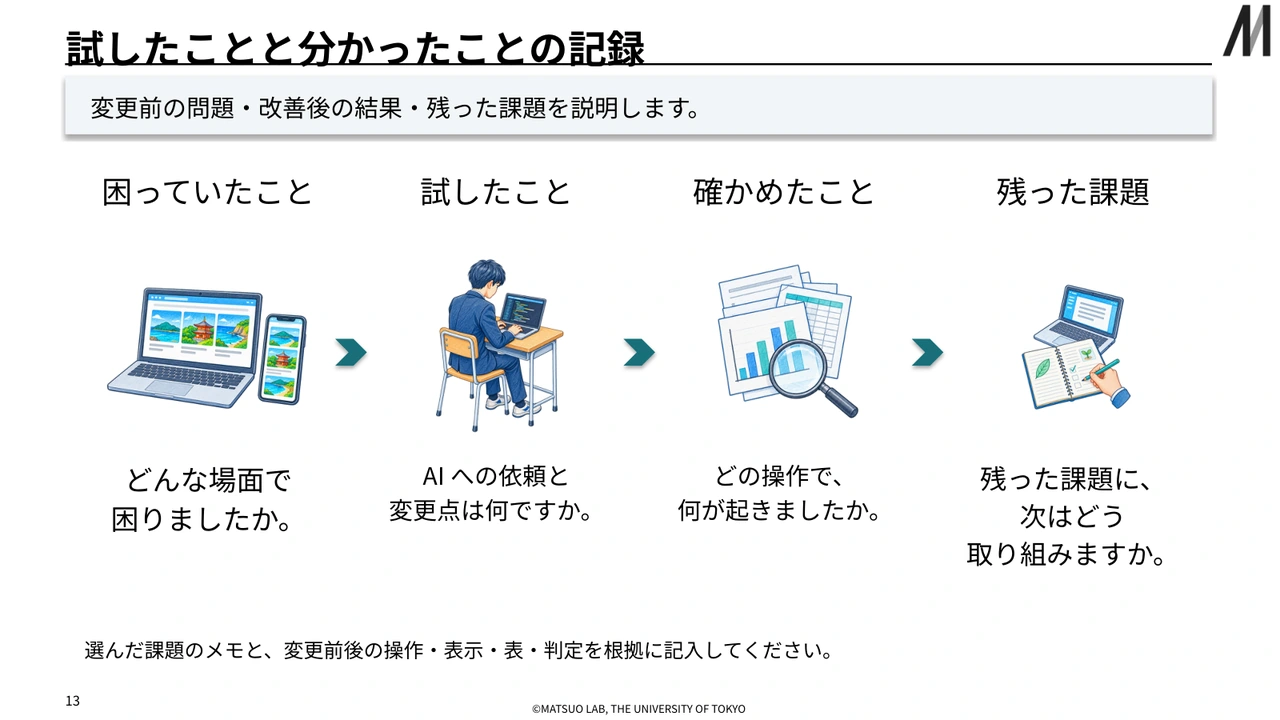

選んだ課題の「試したこと・結果のメモ」を見返してください。変更前後に試した操作や、表示・表・判定の結果を根拠に記入します。

---
課題解決の振り返り<font color="red">＜入力＞</font>

選んだ課題：

困っていたこと・気づいたこと：

AIへ伝え、変えたこと：

操作して確かめたこと・結果：

次に試したいこと：

---

### 出典・教材の設定

まついわの施設・口コミ・観光パス・マスコットは架空です。人物・連絡先を含む口コミも、プライバシーを考えるための架空データです。住所は含めていません。実際のキャンペーン効果を示すデータではありません。

UIにはlibrary-hirobaを使用します。Colabでは準備セルで0.8.3を導入し、PyHirobaでは同梱版を使用します。ライセンスはMITです。
https://github.com/funakoshi-takehiro/library-hiroba

説明イラストと2枚の写真は、本教材用のAI生成画像です。

Fの単語ベクトルは、本教材用の合成観光文から事前学習しました。第三者の学習済みモデルの重みは使用していません。小規模な教材モデルのため、一般的な日本語の検索性能を示すものではありません。学習文・生成コード・条件は配布セットに含まれます。

word2vecの学習方法の参考：Mikolovほか（2013）「Distributed Representations of Words and Phrases and their Compositionality」第2.2節。
https://arxiv.org/abs/1310.4546